<a href="https://colab.research.google.com/github/Sripriya-26/Python/blob/main/notebookc12cd2097e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
edwincaleb_food_crop_price_prediction_beginner_project_path = kagglehub.notebook_output_download('edwincaleb/food-crop-price-prediction-beginner-project')
sivantm_crop_price_prediction_path = kagglehub.notebook_output_download('sivantm/crop-price-prediction')
emrearslan123_house_price_prediction_path = kagglehub.notebook_output_download('emrearslan123/house-price-prediction')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os

for root, dirs, files in os.walk('/kaggle/input'):

    for file in files:

        print(os.path.join(root, file))

/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__notebook__.ipynb
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__output__.json
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results__.html
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/custom.css
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__results___10_0.png
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__results___12_0.png
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__results___13_0.png
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__results___14_0.png
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__results___20_0.png
/kaggle/input/notebooks/ferhatmetin34/used-car-dataset-price-prediction/__results___files/__re

In [ ]:
import os

print("Kaggle Input Directory:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)

    for file in files:
        print("File:", os.path.join(root, file))

Kaggle Input Directory:

Folder: /kaggle/input
Folder: /kaggle/input/notebooks
Folder: /kaggle/input/notebooks/sivantm
Folder: /kaggle/input/notebooks/sivantm/crop-price-prediction
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/__notebook__.ipynb
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/__output__.json
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/__results__.html
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/__resultx__.html
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/custom.css
Folder: /kaggle/input/notebooks/sivantm/crop-price-prediction/__results___files
File: /kaggle/input/notebooks/sivantm/crop-price-prediction/__results___files/__results___38_1.png
Folder: /kaggle/input/notebooks/ferhatmetin34
Folder: /kaggle/input/notebooks/mohaiminul101
Folder: /kaggle/input/notebooks/emrearslan123
Folder: /kaggle/input/notebooks/emrearslan123/house-price-prediction
File: /kaggle/input/notebooks/emrearslan123/house-pri

In [ ]:
import os
import glob
import time
import warnings

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
data_path = '/kaggle/input/notebooks/edwincaleb/food-crop-price-prediction-beginner-project'

# Search for supported data files
extensions = ['csv', 'xlsx', 'xls', 'parquet', 'json']

data_files = []

for ext in extensions:
    data_files.extend(
        glob.glob(
            '/kaggle/input/**/*.' + ext,
            recursive=True
        )
    )

print("Available data files:")

for i, file in enumerate(data_files):
    print(i, file)

if not data_files:
    print("No dataset files found.")
    print("Please check the Kaggle Input section.")
else:
    print("\nAvailable files:", len(data_files))

Available data files:
0 /kaggle/input/notebooks/edwincaleb/food-crop-price-prediction-beginner-project/Food_Crops(EDA_cleaned).csv
1 /kaggle/input/notebooks/sivantm/crop-price-prediction/__output__.json
2 /kaggle/input/notebooks/emrearslan123/house-price-prediction/__output__.json
3 /kaggle/input/notebooks/edwincaleb/food-crop-price-prediction-beginner-project/__output__.json

Available files: 4


In [ ]:
if not data_files:
    raise FileNotFoundError(
        "No CSV, Excel, Parquet or JSON dataset found. "
        "Add the actual dataset through Kaggle Add Input."
    )

file_path = data_files[0]

if file_path.endswith('.csv'):
    df = pd.read_csv(file_path)

elif file_path.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(file_path)

elif file_path.endswith('.parquet'):
    df = pd.read_parquet(file_path)

elif file_path.endswith('.json'):
    df = pd.read_json(file_path)

print("Dataset loaded successfully!")
print("File:", file_path)
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: /kaggle/input/notebooks/edwincaleb/food-crop-price-prediction-beginner-project/Food_Crops(EDA_cleaned).csv
Dataset Shape: (1145, 15)


,Unnamed: 0,Produce_Variety,Commodity_Type,Unit,Volume_in_Kgs,Values_in_Ksh,Date,produce_variety,Type_of_Commodity,Package_Type,package_weight(Kg),Day,Month,Year,Price
0,0,Horticulture,Cabbages,Ext Bag,126,KES2205.00,01/01/2012,1,5,2,126,1,1,2012,2205.0
1,1,Horticulture,Cooking Bananas,Med Bunch,22,KES511.00,01/01/2012,1,11,4,22,1,1,2012,511.0
2,2,Horticulture,Ripe Bananas,Med Bunch,14,KES616.00,01/01/2012,1,34,4,14,1,1,2012,616.0
3,3,Horticulture,Carrots,Ext Bag,138,KES2833.00,01/01/2012,1,7,2,138,1,1,2012,2833.0
4,4,Horticulture,Tomatoes,Lg Box,64,KES3411.00,01/01/2012,1,38,3,64,1,1,2012,3411.0


In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

Number of Rows: 1145
Number of Columns: 15

Column Names:
['Unnamed: 0', 'Produce_Variety', 'Commodity_Type', 'Unit', 'Volume_in_Kgs', 'Values_in_Ksh', 'Date', 'produce_variety', 'Type_of_Commodity', 'Package_Type', 'package_weight(Kg)', 'Day', 'Month', 'Year', 'Price']

Data Types:
Unnamed: 0              int64
Produce_Variety        object
Commodity_Type         object
Unit                   object
Volume_in_Kgs           int64
Values_in_Ksh          object
Date                   object
produce_variety         int64
Type_of_Commodity       int64
Package_Type            int64
package_weight(Kg)      int64
Day                     int64
Month                   int64
Year                    int64
Price                 float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1145.0,NaN,NaN,NaN,572.0,330.677335,0.0,286.0,572.0,858.0,1144.0
Produce_Variety,1145,4,Horticulture,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Commodity_Type,1145,41,Cabbages,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit,1145,8,Bag,780,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Volume_in_Kgs,1145.0,NaN,NaN,NaN,73.370306,36.564162,13.0,50.0,90.0,95.0,142.0
Values_in_Ksh,1143,1017,KES2969.00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,1145,36,05/01/2013,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
produce_variety,1145.0,NaN,NaN,NaN,1.251528,0.752362,0.0,1.0,1.0,2.0,3.0
Type_of_Commodity,1145.0,NaN,NaN,NaN,20.024454,11.773552,0.0,10.0,21.0,30.0,40.0
Package_Type,1145.0,NaN,NaN,NaN,1.233188,2.114043,0.0,0.0,0.0,2.0,7.0


,Missing Count,Missing Percentage
Unnamed: 0,0,0.000000
Produce_Variety,0,0.000000
Commodity_Type,0,0.000000
Unit,0,0.000000
Volume_in_Kgs,0,0.000000
Values_in_Ksh,2,0.174672
Date,0,0.000000
produce_variety,0,0.000000
Type_of_Commodity,0,0.000000
Package_Type,0,0.000000


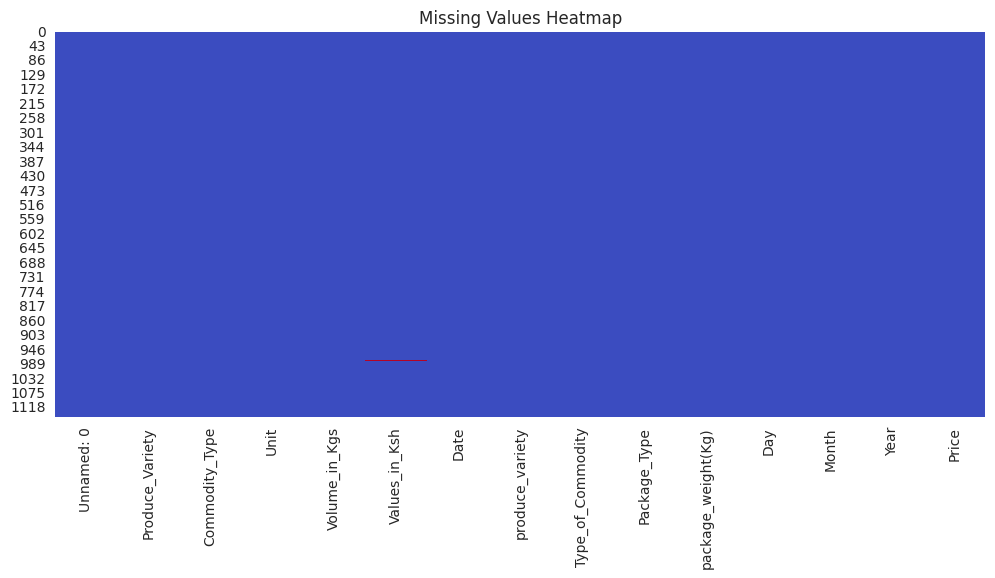

In [ ]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': (
        missing / len(df) * 100
    )
})

display(missing_df)

plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='coolwarm'
)

plt.title("Missing Values Heatmap")
plt.show()

In [ ]:
print("Total Duplicate Records:", df.duplicated().sum())

display(df[df.duplicated()].head())

Total Duplicate Records: 0


,Unnamed: 0,Produce_Variety,Commodity_Type,Unit,Volume_in_Kgs,Values_in_Ksh,Date,produce_variety,Type_of_Commodity,Package_Type,package_weight(Kg),Day,Month,Year,Price


In [ ]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numeric_cols)

print("\nCategorical Features:")
print(categorical_cols)

Numerical Features:
['Unnamed: 0', 'Volume_in_Kgs', 'produce_variety', 'Type_of_Commodity', 'Package_Type', 'package_weight(Kg)', 'Day', 'Month', 'Year', 'Price']

Categorical Features:
['Produce_Variety', 'Commodity_Type', 'Unit', 'Values_in_Ksh', 'Date']


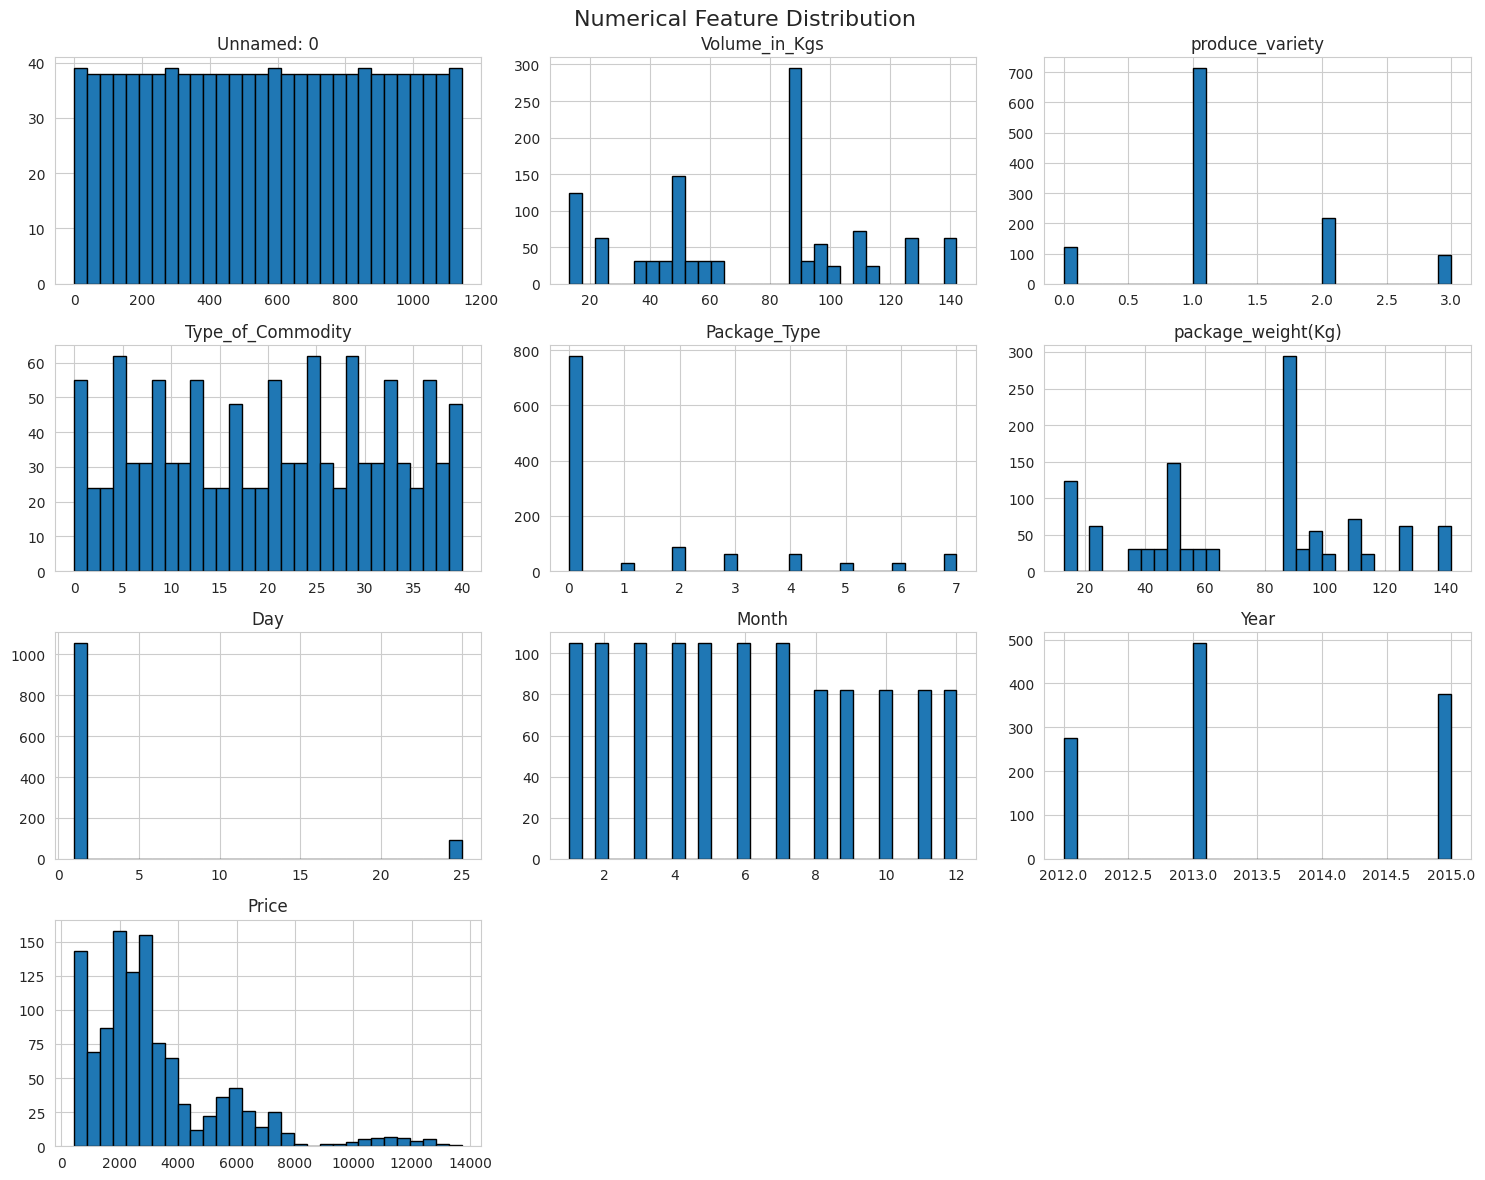

In [ ]:
if numeric_cols:

    df[numeric_cols].hist(
        figsize=(15, 12),
        bins=30,
        edgecolor='black'
    )

    plt.suptitle(
        "Numerical Feature Distribution",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

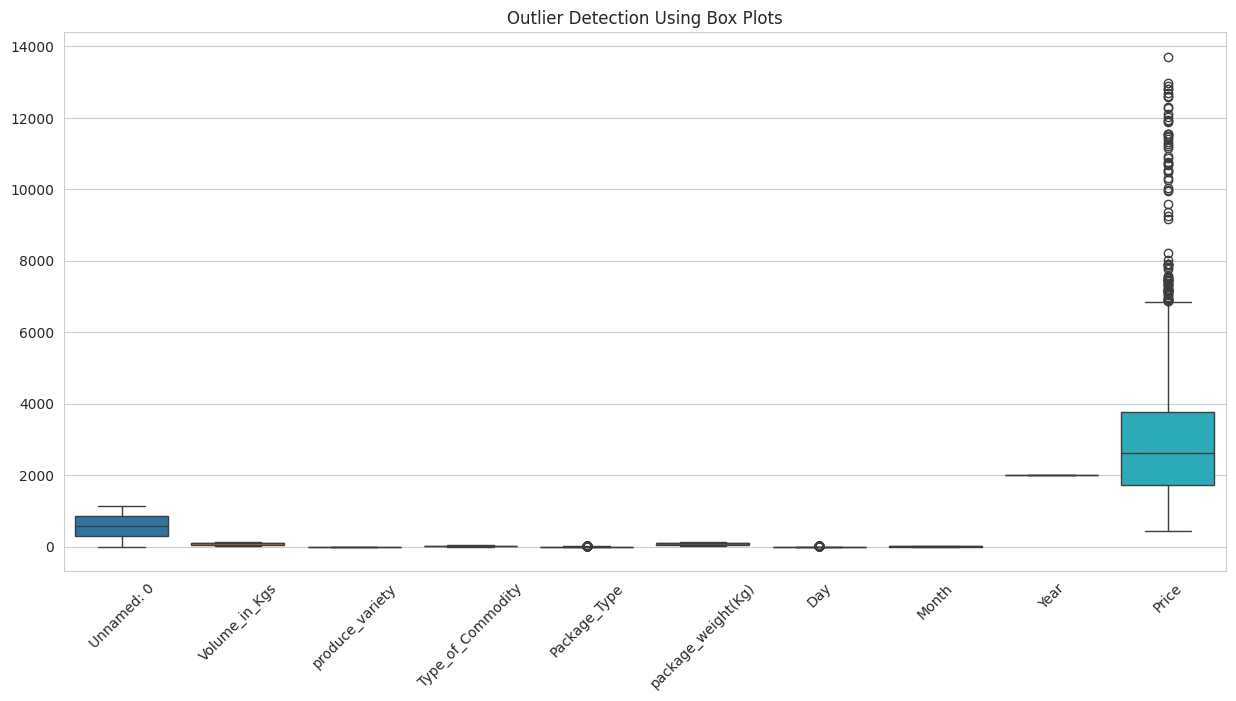

In [ ]:
if numeric_cols:

    plt.figure(figsize=(15, 7))

    sns.boxplot(data=df[numeric_cols])

    plt.title("Outlier Detection Using Box Plots")
    plt.xticks(rotation=45)

    plt.show()

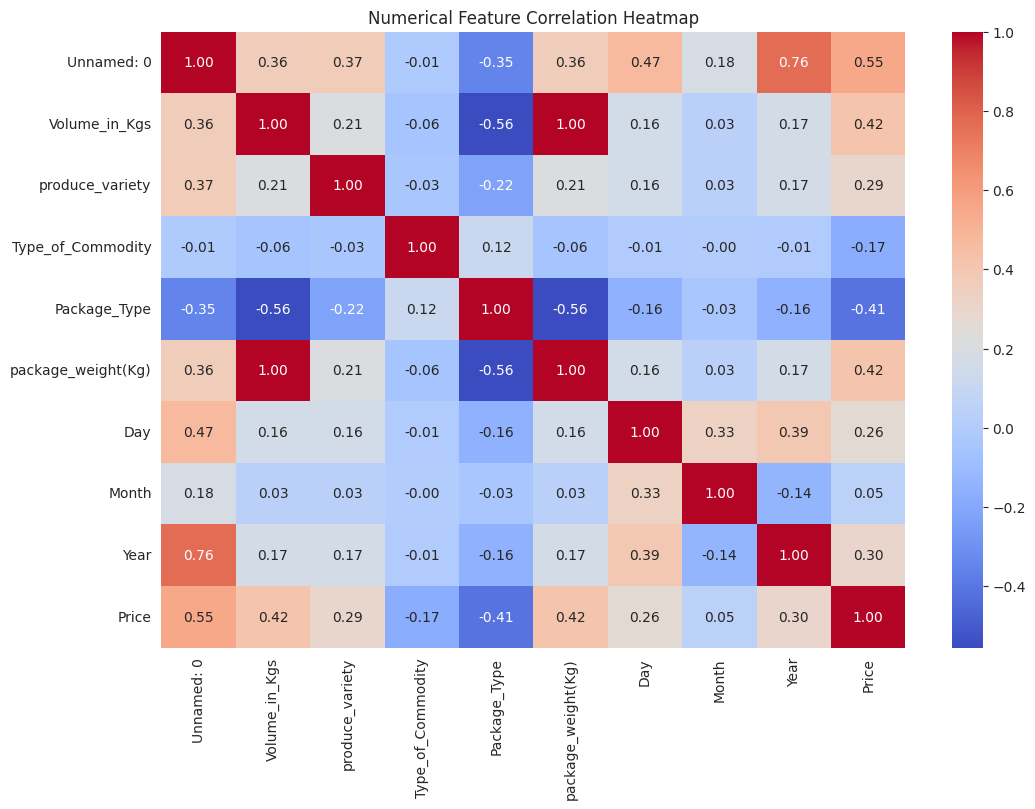

In [ ]:
if len(numeric_cols) > 1:

    plt.figure(figsize=(12, 8))

    correlation = df[numeric_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap='coolwarm',
        fmt='.2f'
    )

    plt.title("Numerical Feature Correlation Heatmap")
    plt.show()

In [ ]:
for col in categorical_cols:

    print("\nFeature:", col)

    print(
        df[col].value_counts().head(15)
    )


Feature: Produce_Variety
Produce_Variety
Horticulture      713
Legumes           216
Cereals           120
Roots & Tubers     96
Name: count, dtype: int64

Feature: Commodity_Type
Commodity_Type
Cabbages           31
Cooking Bananas    31
Ripe Bananas       31
Carrots            31
Tomatoes           31
Onions Dry         31
Spring Onions      31
Chillies           31
Cucumber           31
Capsicums          31
Brinjals           31
Cauliflower        31
Lettuce            31
Passion Fruits     31
Oranges            31
Name: count, dtype: int64

Feature: Unit
Unit
Bag          780
Ext Bag       86
Lg Box        62
Med Bunch     62
net           62
crate         31
Sm Basket     31
Dozen         31
Name: count, dtype: int64

Feature: Values_in_Ksh
Values_in_Ksh
KES2969.00    5
KES2967.00    4
KES2072.00    3
KES2515.00    3
KES2097.00    3
KES570.00     3
KES3553.00    3
KES1993.00    3
KES2653.00    3
KES1938.00    2
KES2377.00    2
KES6525.00    2
KES2490.00    2
KES7916.00    2
KES5

In [ ]:
print("Available Columns:")
print(df.columns.tolist())

Available Columns:
['Unnamed: 0', 'Produce_Variety', 'Commodity_Type', 'Unit', 'Volume_in_Kgs', 'Values_in_Ksh', 'Date', 'produce_variety', 'Type_of_Commodity', 'Package_Type', 'package_weight(Kg)', 'Day', 'Month', 'Year', 'Price']


In [ ]:
target_candidates = [
    'modal_price',
    'modal price',
    'price',
    'selling_price',
    'selling price',
    'retail_price',
    'retail price',
    'target'
]

target_col = next(
    (
        col for col in df.columns
        if col.lower().strip() in target_candidates
    ),
    None
)

print("Detected Target Column:", target_col)

Detected Target Column: Price


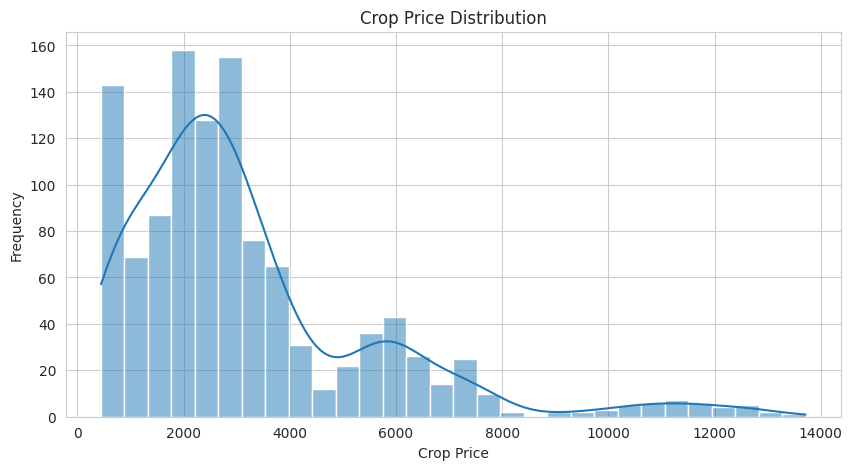

In [ ]:
if target_col is None:
    raise ValueError(
        "Please manually specify the price target column."
    )

plt.figure(figsize=(10, 5))

sns.histplot(
    df[target_col].dropna(),
    kde=True,
    bins=30
)

plt.title("Crop Price Distribution")
plt.xlabel("Crop Price")
plt.ylabel("Frequency")

plt.show()

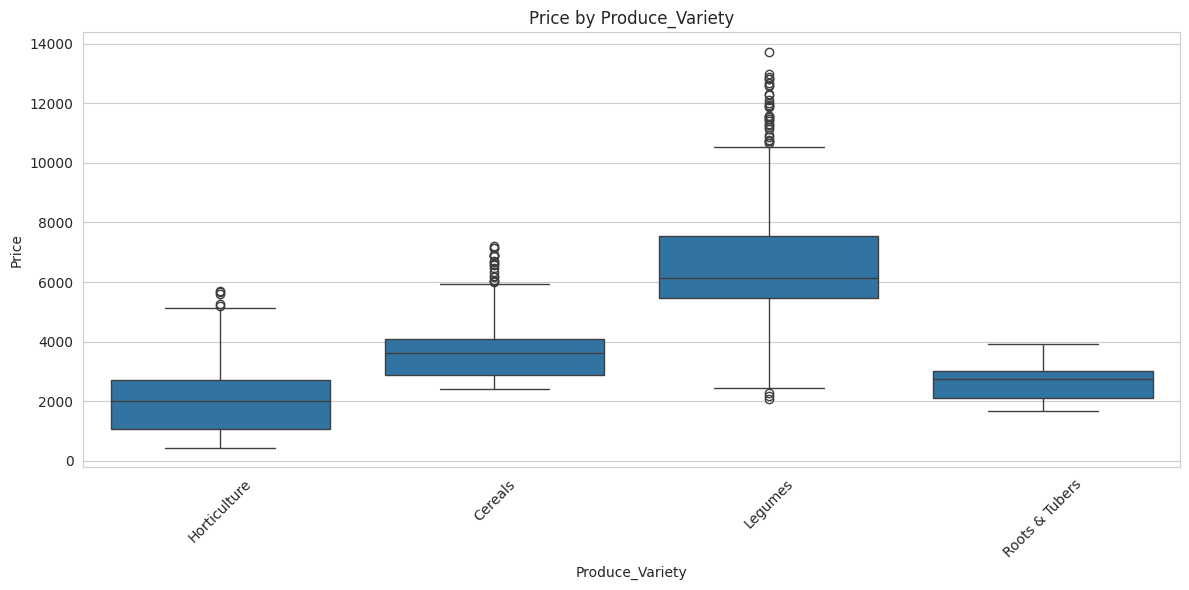

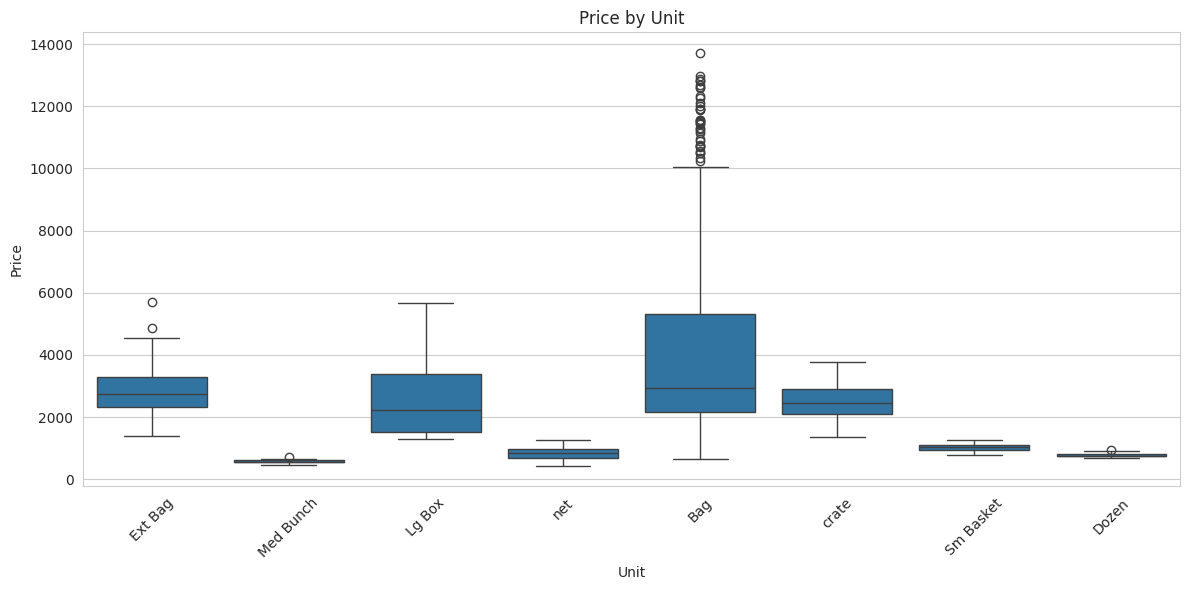

In [ ]:
for col in categorical_cols[:5]:

    if df[col].nunique() <= 20:

        plt.figure(figsize=(12, 6))

        sns.boxplot(
            data=df,
            x=col,
            y=target_col
        )

        plt.title(f"{target_col} by {col}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [ ]:
# Convert target to numerical values
df[target_col] = pd.to_numeric(
    df[target_col].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

# Remove records where target price is missing
df = df.dropna(subset=[target_col]).copy()

# Separate input and target
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Price Statistics:")
display(y.describe())

Input Shape: (1145, 14)
Target Shape: (1145,)

Target Price Statistics:


count     1145.000000
mean      3188.371829
std       2376.371660
min        443.000000
25%       1720.000000
50%       2610.000000
75%       3776.000000
max      13713.000000
Name: Price, dtype: float64

In [ ]:
date_columns = [
    col for col in X.columns
    if 'date' in col.lower()
]

for col in date_columns:

    X[col] = pd.to_datetime(
        X[col],
        errors='coerce',
        dayfirst=True
    )

    X[col + '_year'] = X[col].dt.year
    X[col + '_month'] = X[col].dt.month
    X[col + '_day'] = X[col].dt.day
    X[col + '_dayofweek'] = X[col].dt.dayofweek

    X.drop(columns=[col], inplace=True)

print("Date feature engineering completed.")
display(X.head())

Date feature engineering completed.


,Unnamed: 0,Produce_Variety,Commodity_Type,Unit,Volume_in_Kgs,Values_in_Ksh,produce_variety,Type_of_Commodity,Package_Type,package_weight(Kg),Day,Month,Year,Date_year,Date_month,Date_day,Date_dayofweek
0,0,Horticulture,Cabbages,Ext Bag,126,KES2205.00,1,5,2,126,1,1,2012,2012.0,1.0,1.0,6.0
1,1,Horticulture,Cooking Bananas,Med Bunch,22,KES511.00,1,11,4,22,1,1,2012,2012.0,1.0,1.0,6.0
2,2,Horticulture,Ripe Bananas,Med Bunch,14,KES616.00,1,34,4,14,1,1,2012,2012.0,1.0,1.0,6.0
3,3,Horticulture,Carrots,Ext Bag,138,KES2833.00,1,7,2,138,1,1,2012,2012.0,1.0,1.0,6.0
4,4,Horticulture,Tomatoes,Lg Box,64,KES3411.00,1,38,3,64,1,1,2012,2012.0,1.0,1.0,6.0


In [ ]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Unnamed: 0', 'Volume_in_Kgs', 'produce_variety', 'Type_of_Commodity', 'Package_Type', 'package_weight(Kg)', 'Day', 'Month', 'Year', 'Date_year', 'Date_month', 'Date_day', 'Date_dayofweek']

Categorical Features:
['Produce_Variety', 'Commodity_Type', 'Unit', 'Values_in_Ksh']


In [ ]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Data: (916, 17)
Testing Data: (229, 17)
Training Samples: 916
Testing Samples: 229


In [ ]:
models = {

    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=None,
        min_samples_split=2,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Total Models:", len(models))

for name, model in models.items():
    print("\n", name)
    print(model)

Total Models: 5

 Linear Regression
LinearRegression()

 Decision Tree
DecisionTreeRegressor(random_state=42)

 Random Forest
RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

 Gradient Boosting
GradientBoostingRegressor(random_state=42)

 Extra Trees
ExtraTreesRegressor(n_estimators=200, n_jobs=-1, random_state=42)


In [ ]:
results = []
trained_models = {}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models.items():

    print("\n================================")
    print("Training:", name)
    print("================================")

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Training time
    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    # Cross-validation
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    # MAPE (excluding zero actual prices)
    nonzero_mask = y_test != 0

    mape = (
        np.mean(
            np.abs(
                (y_test[nonzero_mask] -
                 y_pred[nonzero_mask]) /
                y_test[nonzero_mask]
            )
        ) * 100
        if nonzero_mask.any()
        else np.nan
    )

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2,
        'MAPE (%)': mape,
        'CV Mean R2': cv_scores.mean(),
        'CV Std': cv_scores.std(),
        'Training Time (sec)': training_time
    })

    trained_models[name] = pipeline

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))
    print("MAPE:", round(mape, 2), "%")
    print("CV Mean R2:", round(cv_scores.mean(), 4))
    print("Training Time:", round(training_time, 3), "seconds")

print("\nAll five models trained successfully!")


Training: Linear Regression
MAE: 835.86
RMSE: 1443.35
R2 Score: 0.6344
MAPE: 30.64 %
CV Mean R2: 0.5974
Training Time: 0.07 seconds

Training: Decision Tree
MAE: 247.64
RMSE: 365.28
R2 Score: 0.9766
MAPE: 11.28 %
CV Mean R2: 0.963
Training Time: 0.036 seconds

Training: Random Forest
MAE: 219.31
RMSE: 340.35
R2 Score: 0.9797
MAPE: 8.93 %
CV Mean R2: 0.9671
Training Time: 1.056 seconds

Training: Gradient Boosting
MAE: 324.8
RMSE: 490.54
R2 Score: 0.9578
MAPE: 15.02 %
CV Mean R2: 0.9576
Training Time: 0.272 seconds

Training: Extra Trees
MAE: 216.45
RMSE: 336.42
R2 Score: 0.9801
MAPE: 9.3 %
CV Mean R2: 0.9704
Training Time: 1.255 seconds

All five models trained successfully!


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='CV Mean R2',
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        'MAE': '{:.2f}',
        'RMSE': '{:.2f}',
        'R2 Score': '{:.4f}',
        'MAPE (%)': '{:.2f}',
        'CV Mean R2': '{:.4f}',
        'CV Std': '{:.4f}',
        'Training Time (sec)': '{:.3f}'
    })
)

,Model,MAE,RMSE,R2 Score,MAPE (%),CV Mean R2,CV Std,Training Time (sec)
0,Extra Trees,216.45,336.42,0.9801,9.30,0.9704,0.0055,1.255
1,Random Forest,219.31,340.35,0.9797,8.93,0.9671,0.0070,1.056
2,Decision Tree,247.64,365.28,0.9766,11.28,0.9630,0.0070,0.036
3,Gradient Boosting,324.80,490.54,0.9578,15.02,0.9576,0.0049,0.272
4,Linear Regression,835.86,1443.35,0.6344,30.64,0.5974,0.1459,0.070


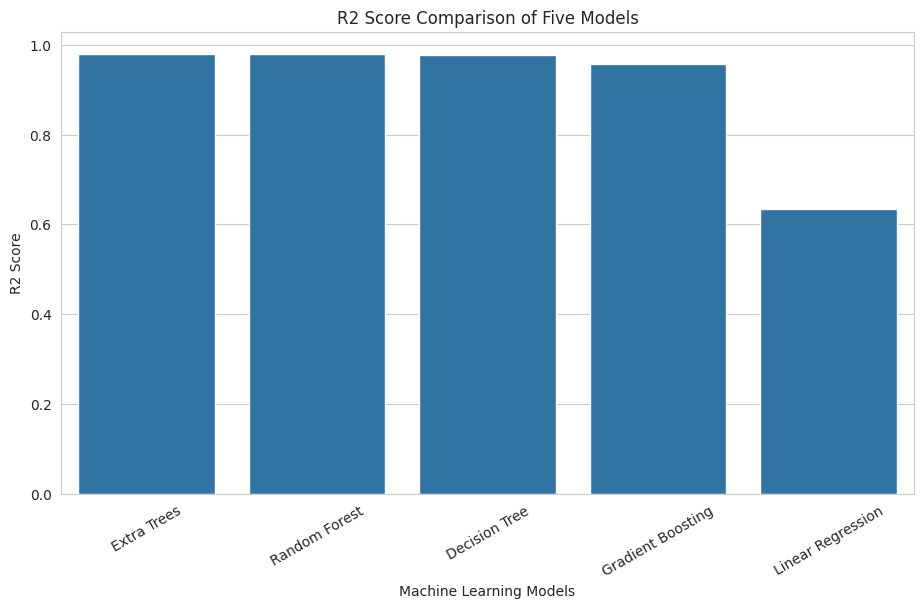

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("R2 Score Comparison of Five Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=30)
plt.show()

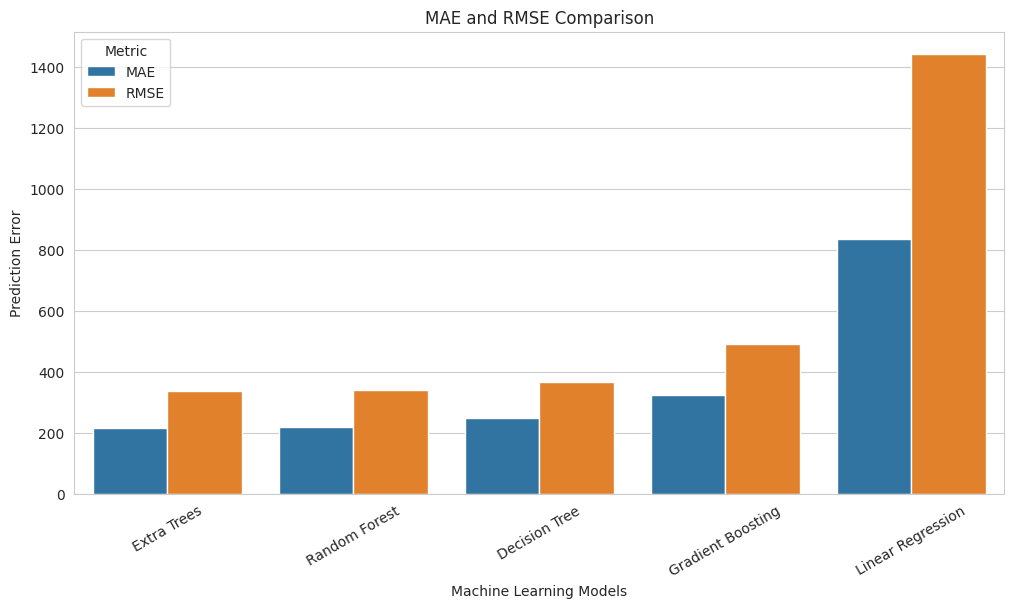

In [ ]:
comparison = results_df.melt(
    id_vars='Model',
    value_vars=['MAE', 'RMSE'],
    var_name='Metric',
    value_name='Error'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison,
    x='Model',
    y='Error',
    hue='Metric'
)

plt.title("MAE and RMSE Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Prediction Error")

plt.xticks(rotation=30)
plt.show()

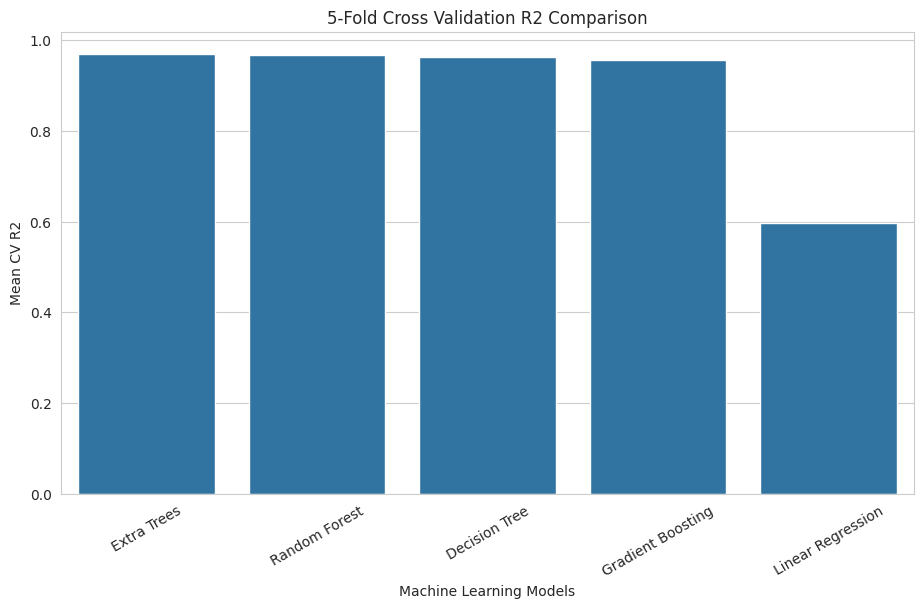

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='CV Mean R2'
)

plt.title("5-Fold Cross Validation R2 Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean CV R2")

plt.xticks(rotation=30)
plt.show()

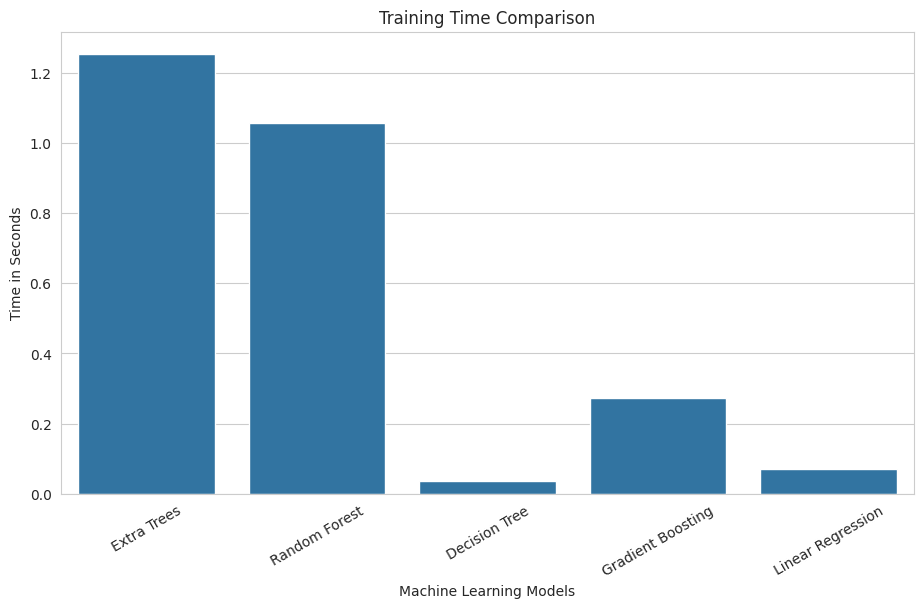

In [ ]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Training Time (sec)'
)

plt.title("Training Time Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Time in Seconds")

plt.xticks(rotation=30)
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("====================================")
print("          BEST MODEL")
print("====================================")

print("Best Algorithm:", best_model_name)

print(
    "Cross Validation R2:",
    round(results_df.iloc[0]['CV Mean R2'], 4)
)

print(
    "Test R2:",
    round(results_df.iloc[0]['R2 Score'], 4)
)

print(
    "Test MAE:",
    round(results_df.iloc[0]['MAE'], 2)
)

print(
    "Test RMSE:",
    round(results_df.iloc[0]['RMSE'], 2)
)

print("====================================")

          BEST MODEL
Best Algorithm: Extra Trees
Cross Validation R2: 0.9704
Test R2: 0.9801
Test MAE: 216.45
Test RMSE: 336.42


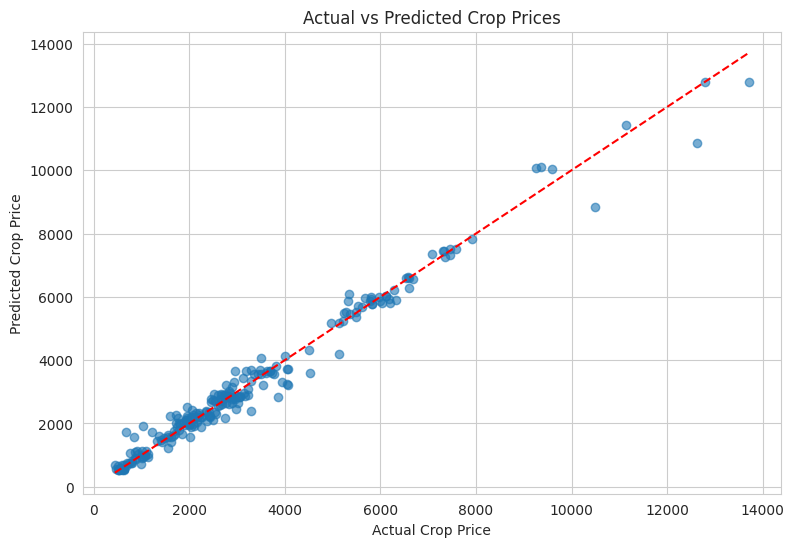

In [ ]:
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.6
)

min_value = min(y_test.min(), y_pred_best.min())
max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--'
)

plt.xlabel("Actual Crop Price")
plt.ylabel("Predicted Crop Price")

plt.title("Actual vs Predicted Crop Prices")

plt.show()

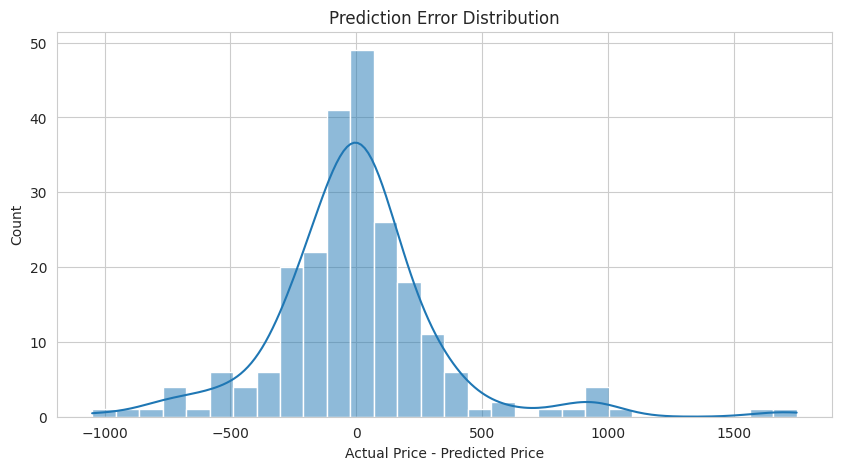

In [ ]:
residuals = y_test - y_pred_best

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.title("Prediction Error Distribution")
plt.xlabel("Actual Price - Predicted Price")

plt.show()

In [ ]:
# Use one actual test record as an example
sample_input = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = best_model.predict(sample_input)[0]

print("================================")
print("       CROP PRICE PREDICTION")
print("================================")

print("Actual Price:", round(actual_price, 2))

print("Predicted Price:", round(predicted_price, 2))

print(
    "Absolute Error:",
    round(abs(actual_price - predicted_price), 2)
)

print("================================")

       CROP PRICE PREDICTION
Actual Price: 1883.0
Predicted Price: 2060.85
Absolute Error: 177.85
